# LLM Foundations: Tokens, Embeddings, Attention and the Transformer Block

**Purpose**: hands-on, CPU-sized implementations of the concepts in Chapter 1: tokenization, embeddings and positional encodings, scaled dot-product and multi-head attention, a transformer block, and the causal language-modeling objective. Training dynamics, optimization and scaling laws live in the Chapter 2 notebook.

**Companion Theory**: This notebook works alongside the [Foundations chapter](../index.md) which gives the full explanations and derivations, whose later tokenization sections cover tokenizer algorithms and practice.

**Learning Path**: 
1. Read theory sections in the main chapter
2. Run corresponding notebook cells for hands-on practice  
3. Return to chapter for deeper understanding

**Dependencies**: PyTorch (CPU), NumPy, Matplotlib, Seaborn

**Reproducibility**: a fixed seed is set in the setup cell and the vocabulary is built in sorted order, so running the cells top to bottom gives identical outputs. The modules here are untrained (random weights): the attention maps and embedding similarities show structure of the *mechanism*, not learned linguistic knowledge. Cells contain `assert` statements that fail loudly if a claimed property does not hold.

**Primary Sources**: 
- Vaswani et al., 2017 - "Attention Is All You Need" ([arXiv:1706.03762](https://arxiv.org/abs/1706.03762))
- Su et al., 2021 - "RoFormer: Enhanced Transformer with Rotary Position Embedding" ([arXiv:2104.09864](https://arxiv.org/abs/2104.09864))
- Shaw et al., 2018 - "Self-Attention with Relative Position Representations" ([arXiv:1803.02155](https://arxiv.org/abs/1803.02155))



## 1. Import Required Libraries

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from typing import Optional, Tuple

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Configure plotting
plt.style.use('default')
sns.set_palette("husl")

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.14.1+cpu
NumPy version: 2.5.4
Device: cpu


(nb-attn-tokenization)=
## 2. Tokenization and Embeddings

Text becomes integers (tokens), integers become vectors (embeddings), and a positional signal is added so the model can tell order.

$$\mathbf{x}_i = \sqrt{d}\,E[\text{token}_i] + PE_i,\qquad PE_{(pos,2i)} = \sin\frac{pos}{10000^{2i/d}},\; PE_{(pos,2i+1)} = \cos\frac{pos}{10000^{2i/d}}$$

This section uses a deliberately tiny word-level tokenizer so that every later tensor is small enough to print. Subword algorithms (BPE, unigram) are covered in the chapter's tokenization sections; the next cell shows the core BPE merge loop.


In [2]:
# Simple tokenization example
def simple_tokenizer(text: str) -> list:
    """Basic word-level tokenization."""
    return text.lower().split()

# Create a simple vocabulary
sample_text = "the quick brown fox jumps over the lazy dog"
tokens = simple_tokenizer(sample_text)
vocab = {word: idx for idx, word in enumerate(sorted(set(tokens)))}  # sorted: hash order is not reproducible
vocab['<UNK>'] = len(vocab)  # Unknown token
vocab_size = len(vocab)

print("Sample tokens:", tokens)
print("Vocabulary:", vocab)
print("Vocabulary size:", vocab_size)

# Token to ID conversion
def tokenize(text: str) -> list:
    """Convert text to token IDs."""
    tokens = simple_tokenizer(text)
    return [vocab.get(token, vocab['<UNK>']) for token in tokens]

# Test tokenization
test_text = "the fox jumps"
token_ids = tokenize(test_text)
print(f"\nText: '{test_text}'")
print(f"Token IDs: {token_ids}")

Sample tokens: ['the', 'quick', 'brown', 'fox', 'jumps', 'over', 'the', 'lazy', 'dog']
Vocabulary: {'brown': 0, 'dog': 1, 'fox': 2, 'jumps': 3, 'lazy': 4, 'over': 5, 'quick': 6, 'the': 7, '<UNK>': 8}
Vocabulary size: 9

Text: 'the fox jumps'
Token IDs: [7, 2, 3]


### Byte-pair encoding, the merge loop

BPE starts from characters and repeatedly merges the most frequent adjacent pair. The printout shows the splits after each merge (tokens separated by spaces), so you can watch the merges happen.


In [3]:
# Simplified BPE demonstration (educational version)
from collections import defaultdict, Counter

def simple_bpe_demo():
    """Demonstrate basic BPE algorithm concepts."""
    
    # Sample corpus
    corpus = ["hello", "world", "help", "held", "helicopter"]
    
    print("=== Simplified BPE Demonstration ===")
    print(f"Corpus: {corpus}")
    
    # Step 1: Initialize with character vocabulary
    word_freqs = Counter(corpus)
    
    # Convert to character sequences with end-of-word marker
    word_splits = {}
    for word, freq in word_freqs.items():
        word_splits[tuple(word) + ('</w>',)] = freq
    
    print(f"\nInitial character splits:")
    for word, freq in word_splits.items():
        print(f"  {' '.join(word)} (freq: {freq})")
    
    # Step 2: Find most frequent adjacent pairs
    def get_pairs(word_splits):
        pairs = defaultdict(int)
        for word, freq in word_splits.items():
            for i in range(len(word) - 1):
                pairs[(word[i], word[i + 1])] += freq
        return pairs
    
    def merge_pair(word_splits, pair):
        new_word_splits = {}
        for word, freq in word_splits.items():
            new_word = []
            i = 0
            while i < len(word):
                if i < len(word) - 1 and word[i] == pair[0] and word[i + 1] == pair[1]:
                    new_word.append(''.join(pair))
                    i += 2
                else:
                    new_word.append(word[i])
                    i += 1
            new_word_splits[tuple(new_word)] = freq
        return new_word_splits
    
    # Perform a few BPE merges
    for iteration in range(3):
        pairs = get_pairs(word_splits)
        if not pairs:
            break
            
        best_pair = max(pairs, key=pairs.get)
        word_splits = merge_pair(word_splits, best_pair)
        
        print(f"\nIteration {iteration + 1}: Merged '{best_pair[0]}' + '{best_pair[1]}' -> '{best_pair[0] + best_pair[1]}'")
        for word, freq in word_splits.items():
            print(f"  {' '.join(word)} (freq: {freq})")
    
    return word_splits

# Run BPE demo
bpe_result = simple_bpe_demo()

# Demonstrate why whitespace splitting is not a tokenizer
print("\n=== Whitespace splitting on other scripts and text types ===")
print("(simple_tokenizer splits on spaces, so scripts without spaces become one token)")

# Different languages
multilingual_examples = {
    "English": "Hello world",
    "German": "Donaudampfschifffahrt",  # Compound word
    "Chinese": "我喜欢学习",  # No spaces
    "Arabic": "مرحبا بالعالم",  # Right-to-left
}

for lang, text in multilingual_examples.items():
    tokens = simple_tokenizer(text)
    print(f"{lang}: '{text}' → {tokens} ({len(tokens)} tokens)")

# Special text types
special_examples = {
    "Code": "def hello(): return 'world'",
    "URL": "https://www.example.com/path?param=value",
    "Numbers": "The price is $1,234.56 (12.5% off)",
    "Email": "user.name+tag@example.co.uk"
}

print("\nSpecial text handling:")
for text_type, text in special_examples.items():
    tokens = simple_tokenizer(text)
    print(f"{text_type}: {len(tokens)} tokens")
    print(f"  → {tokens[:5]}{'...' if len(tokens) > 5 else ''}")

=== Simplified BPE Demonstration ===
Corpus: ['hello', 'world', 'help', 'held', 'helicopter']

Initial character splits:
  h e l l o </w> (freq: 1)
  w o r l d </w> (freq: 1)
  h e l p </w> (freq: 1)
  h e l d </w> (freq: 1)
  h e l i c o p t e r </w> (freq: 1)

Iteration 1: Merged 'h' + 'e' -> 'he'
  he l l o </w> (freq: 1)
  w o r l d </w> (freq: 1)
  he l p </w> (freq: 1)
  he l d </w> (freq: 1)
  he l i c o p t e r </w> (freq: 1)

Iteration 2: Merged 'he' + 'l' -> 'hel'
  hel l o </w> (freq: 1)
  w o r l d </w> (freq: 1)
  hel p </w> (freq: 1)
  hel d </w> (freq: 1)
  hel i c o p t e r </w> (freq: 1)

Iteration 3: Merged 'd' + '</w>' -> 'd</w>'
  hel l o </w> (freq: 1)
  w o r l d</w> (freq: 1)
  hel p </w> (freq: 1)
  hel d</w> (freq: 1)
  hel i c o p t e r </w> (freq: 1)

=== Whitespace splitting on other scripts and text types ===
(simple_tokenizer splits on spaces, so scripts without spaces become one token)
English: 'Hello world' → ['hello', 'world'] (2 tokens)
German: 'Donaud

In [4]:
# Embedding layer implementation
class SimpleEmbedding(nn.Module):
    """Simple embedding layer with positional encoding."""
    
    def __init__(self, vocab_size: int, d_model: int, max_seq_length: int = 100):
        super().__init__()
        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = self._create_positional_encoding(max_seq_length, d_model)
        
    def _create_positional_encoding(self, max_seq_length: int, d_model: int) -> torch.Tensor:
        """Create sinusoidal positional encodings."""
        pe = torch.zeros(max_seq_length, d_model)
        position = torch.arange(0, max_seq_length).unsqueeze(1).float()
        
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                           -(math.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        return pe.unsqueeze(0)  # Add batch dimension
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass: embedding + positional encoding."""
        seq_len = x.size(1)
        embeddings = self.embedding(x) * math.sqrt(self.d_model)
        return embeddings + self.pos_encoding[:, :seq_len, :]

# Test embedding layer
d_model = 64
embedding_layer = SimpleEmbedding(vocab_size, d_model)

# Create sample input
input_ids = torch.tensor([tokenize("the quick brown fox")])
embeddings = embedding_layer(input_ids)

print(f"Input shape: {input_ids.shape}")
print(f"Embedding shape: {embeddings.shape}")
print(f"First token embedding (first 8 dims): {embeddings[0, 0, :8]}")

Input shape: torch.Size([1, 4])
Embedding shape: torch.Size([1, 4, 64])
First token embedding (first 8 dims): tensor([-11.0711,   4.8950,  -8.0162,   1.2636,  -3.4336,  -6.8544,  -5.1365,
          7.6127], grad_fn=<SliceBackward0>)


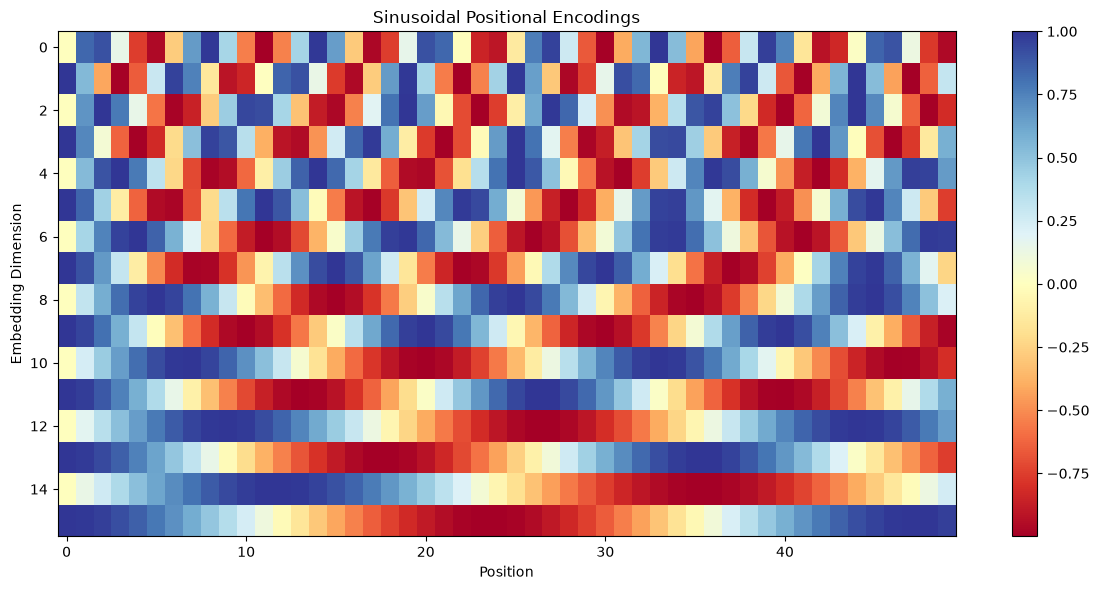

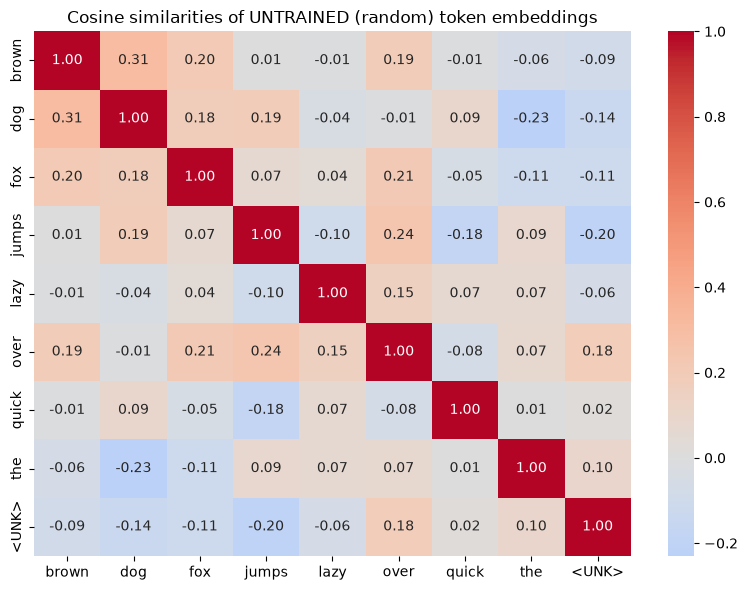

In [5]:
# Visualize positional encodings
def plot_positional_encoding():
    """Visualize sinusoidal positional encodings."""
    pe = embedding_layer.pos_encoding[0, :50, :16]  # First 50 positions, 16 dimensions
    
    plt.figure(figsize=(12, 6))
    plt.imshow(pe.T, cmap='RdYlBu', aspect='auto')
    plt.colorbar()
    plt.xlabel('Position')
    plt.ylabel('Embedding Dimension')
    plt.title('Sinusoidal Positional Encodings')
    plt.tight_layout()
    plt.show()

plot_positional_encoding()

# Visualize embedding similarities
def plot_embedding_similarities():
    """Plot cosine similarities between token embeddings.

    The embedding table is freshly initialised, so these similarities are noise around 0;
    after training, related tokens would show positive similarity."""
    # Get embeddings for our vocabulary
    all_token_ids = torch.tensor([[i for i in range(vocab_size)]])
    all_embeddings = embedding_layer(all_token_ids)[0]  # Remove batch dim
    
    # Compute cosine similarities
    cosine_sim = F.cosine_similarity(
        all_embeddings.unsqueeze(1), 
        all_embeddings.unsqueeze(0), 
        dim=2
    )
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cosine_sim.detach(), 
                xticklabels=list(vocab.keys()),
                yticklabels=list(vocab.keys()),
                cmap='coolwarm', center=0,
                fmt='.2f', annot=True)
    plt.title('Cosine similarities of UNTRAINED (random) token embeddings')
    plt.tight_layout()
    plt.show()

plot_embedding_similarities()

(nb-attn-positional)=
### Learned, relative and rotary positional encodings

Sinusoidal encodings are added to the input. The two modern alternatives act *inside attention*: a learned **relative-position bias** $b_{i-j}$ is added to the scores, and **RoPE** rotates each query/key pair by an angle proportional to its position, so that $q_m \cdot k_n$ depends only on $m-n$:

$$\text{scores}_{ij} = \frac{q_i\cdot k_j}{\sqrt{d_k}} + b_{i-j} \qquad\qquad \mathrm{RoPE}(x, m)_{2i:2i+2} = R(m\theta_i)\,x_{2i:2i+2},\; \theta_i = 10000^{-2i/d}$$


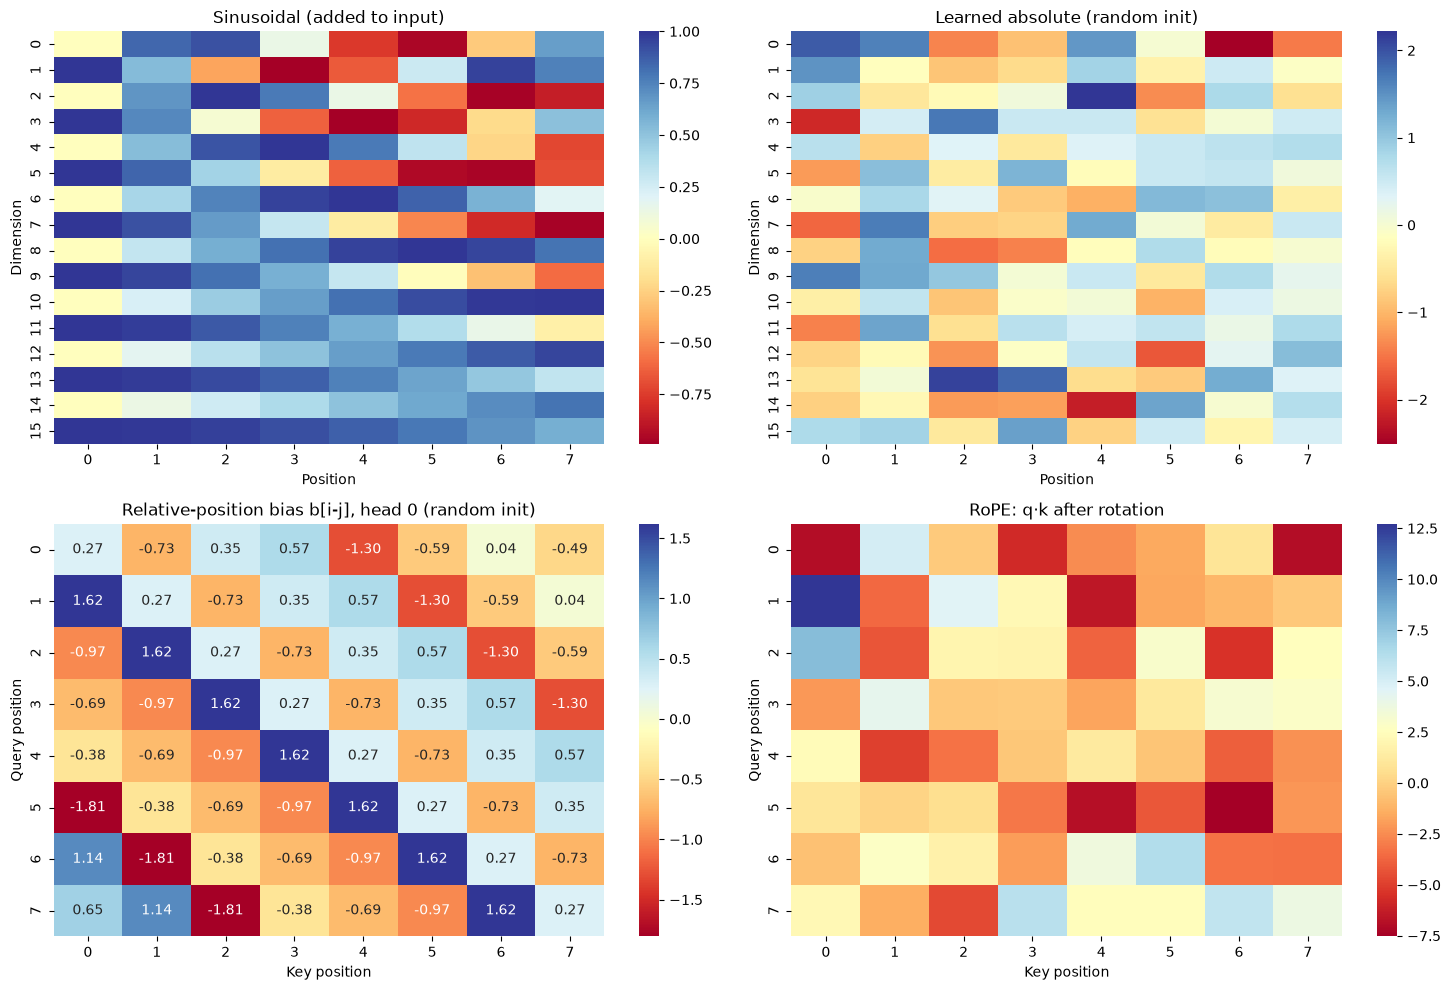

Positional encoding facts (computed above):
1. Sinusoidal: values in [-0.99, 1.00], no parameters
2. Learned absolute: 128 parameters for 8 positions; cannot address position 8 or beyond
3. Relative bias: 42 parameters shared by all positions; offsets beyond ±10 are clamped
4. RoPE: no parameters; norms preserved and q·k unchanged under a common shift (both asserted)


In [6]:
class RelativePositionBias(nn.Module):
    """Learned bias b[i-j] added to attention scores (Shaw et al., 2018; T5-style)."""

    def __init__(self, num_heads: int, max_distance: int = 10):
        super().__init__()
        self.max_distance = max_distance
        self.table = nn.Embedding(2 * max_distance + 1, num_heads)

    def forward(self, seq_len: int) -> torch.Tensor:
        positions = torch.arange(seq_len)
        rel = positions.unsqueeze(0) - positions.unsqueeze(1)
        rel = rel.clamp(-self.max_distance, self.max_distance) + self.max_distance
        return self.table(rel).permute(2, 0, 1)  # [heads, seq, seq]


def apply_rope(x: torch.Tensor, positions: torch.Tensor, base: float = 10000.0) -> torch.Tensor:
    """Rotary position embedding (Su et al., 2021) on the last dim of x: [..., seq, d]."""
    d = x.size(-1)
    inv_freq = 1.0 / (base ** (torch.arange(0, d, 2).float() / d))        # [d/2]
    angles = positions.float()[:, None] * inv_freq[None, :]                # [seq, d/2]
    cos, sin = torch.cos(angles), torch.sin(angles)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2] = x1 * cos - x2 * sin
    out[..., 1::2] = x1 * sin + x2 * cos
    return out


seq_len, d_small, heads = 8, 16, 2
torch.manual_seed(42)

# 1. Sinusoidal (added to the input, from the embedding layer above)
pe_sin = embedding_layer.pos_encoding[0, :seq_len, :d_small]

# 2. Learned absolute embeddings (one vector per position)
pe_learned = nn.Embedding(seq_len, d_small)(torch.arange(seq_len))

# 3. Relative-position bias: one learned scalar per (head, offset), added to the scores
rel_bias = RelativePositionBias(heads)(seq_len)

# 4. RoPE: rotate q and k, then check the two properties that make it useful
q = torch.randn(seq_len, d_small)
k = torch.randn(seq_len, d_small)
pos = torch.arange(seq_len)
q_rot, k_rot = apply_rope(q, pos), apply_rope(k, pos)
assert torch.allclose(q_rot.norm(dim=-1), q.norm(dim=-1), atol=1e-5), "rotation must preserve norms"
# shifting both positions by the same offset leaves every q·k unchanged (relative dependence)
q_shift, k_shift = apply_rope(q, pos + 5), apply_rope(k, pos + 5)
assert torch.allclose(q_rot @ k_rot.T, q_shift @ k_shift.T, atol=1e-4), "q·k must depend only on the relative offset"

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.heatmap(pe_sin.T, cmap='RdYlBu', ax=axes[0, 0]); axes[0, 0].set_title('Sinusoidal (added to input)'); axes[0, 0].set_xlabel('Position'); axes[0, 0].set_ylabel('Dimension')
sns.heatmap(pe_learned.detach().T, cmap='RdYlBu', ax=axes[0, 1]); axes[0, 1].set_title('Learned absolute (random init)'); axes[0, 1].set_xlabel('Position'); axes[0, 1].set_ylabel('Dimension')
sns.heatmap(rel_bias[0].detach(), cmap='RdYlBu', ax=axes[1, 0], annot=True, fmt='.2f'); axes[1, 0].set_title('Relative-position bias b[i-j], head 0 (random init)'); axes[1, 0].set_xlabel('Key position'); axes[1, 0].set_ylabel('Query position')
sns.heatmap((q_rot @ k_rot.T).detach(), cmap='RdYlBu', ax=axes[1, 1]); axes[1, 1].set_title('RoPE: q·k after rotation'); axes[1, 1].set_xlabel('Key position'); axes[1, 1].set_ylabel('Query position')
plt.tight_layout(); plt.show()

print("Positional encoding facts (computed above):")
print(f"1. Sinusoidal: values in [{pe_sin.min():.2f}, {pe_sin.max():.2f}], no parameters")
print(f"2. Learned absolute: {pe_learned.numel()} parameters for {seq_len} positions; cannot address position {seq_len} or beyond")
print(f"3. Relative bias: {rel_bias.numel() // seq_len**2 * (2*10+1)} parameters shared by all positions; offsets beyond ±10 are clamped")
print(f"4. RoPE: no parameters; norms preserved and q·k unchanged under a common shift (both asserted)")


(nb-attn-attention)=
## 3. Attention Mechanisms

$$\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V, \qquad \mathrm{MultiHead} = \mathrm{Concat}(\mathrm{head}_1,\dots,\mathrm{head}_h)W^O$$

Attention (Bahdanau et al., 2014; Vaswani et al., 2017) computes a weighted average of value vectors, with weights given by the compatibility of a query with each key. The modules below are used in **eval mode**: in train mode `nn.Dropout` on the weights rescales the surviving entries by $1/(1-p)$, so the rows would no longer sum to 1.


In [7]:
class ScaledDotProductAttention(nn.Module):
    """Scaled Dot-Product Attention mechanism."""
    
    def __init__(self, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, query: torch.Tensor, key: torch.Tensor, value: torch.Tensor, 
                mask: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Args:
            query: [batch_size, seq_len, d_k]
            key: [batch_size, seq_len, d_k]  
            value: [batch_size, seq_len, d_v]
            mask: [batch_size, seq_len, seq_len] or None
            
        Returns:
            output: [batch_size, seq_len, d_v]
            attention_weights: [batch_size, seq_len, seq_len]
        """
        d_k = query.size(-1)
        
        # Compute attention scores
        scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)
        
        # Apply mask if provided (for causal attention)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, torch.finfo(scores.dtype).min)
        
        # Apply softmax to get attention weights
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)
        
        # Apply attention to values
        output = torch.matmul(attention_weights, value)
        
        return output, attention_weights

# Test self-attention
attention = ScaledDotProductAttention().eval()  # eval: no dropout on the weights

# Use our embeddings as Q, K, V
query = key = value = embeddings  # Self-attention
output, attn_weights = attention(query, key, value)

print(f"Attention output shape: {output.shape}")
print(f"Attention weights shape: {attn_weights.shape}")
row_sums = attn_weights.sum(dim=-1)
assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-5), "attention rows must sum to 1"
print(f"Attention weights row sums: {row_sums}")

Attention output shape: torch.Size([1, 4, 64])
Attention weights shape: torch.Size([1, 4, 4])
Attention weights row sums: tensor([[1., 1., 1., 1.]], grad_fn=<SumBackward1>)


In [8]:
class MultiHeadAttention(nn.Module):
    """Multi-Head Attention mechanism."""
    
    def __init__(self, d_model: int, num_heads: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % num_heads == 0
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        
        # Linear projections for Q, K, V
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        
        self.attention = ScaledDotProductAttention(dropout)
        
    def forward(self, query: torch.Tensor, key: torch.Tensor, value: torch.Tensor,
                mask: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, torch.Tensor]:
        batch_size = query.size(0)
        seq_len = query.size(1)
        
        # 1. Linear projections
        Q = self.w_q(query)
        K = self.w_k(key)
        V = self.w_v(value)
        
        # 2. Reshape for multi-head attention
        Q = Q.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        K = K.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        V = V.view(batch_size, seq_len, self.num_heads, self.d_k).transpose(1, 2)
        
        # 3. Apply attention
        attn_output, attn_weights = self.attention(Q, K, V, mask)
        
        # 4. Concatenate heads
        attn_output = attn_output.transpose(1, 2).contiguous().view(
            batch_size, seq_len, self.d_model)
        
        # 5. Final linear projection
        output = self.w_o(attn_output)
        
        return output, attn_weights

# Test multi-head attention
num_heads = 8
mha = MultiHeadAttention(d_model, num_heads).eval()

# Apply multi-head attention
mha_output, mha_weights = mha(embeddings, embeddings, embeddings)

print(f"Multi-head attention output shape: {mha_output.shape}")
print(f"Multi-head attention weights shape: {mha_weights.shape}")
assert torch.allclose(mha_weights.sum(-1), torch.ones_like(mha_weights.sum(-1)), atol=1e-5)
print(f"Number of attention heads: {num_heads}; every head's rows sum to 1")

Multi-head attention output shape: torch.Size([1, 4, 64])
Multi-head attention weights shape: torch.Size([1, 8, 4, 4])
Number of attention heads: 8; every head's rows sum to 1


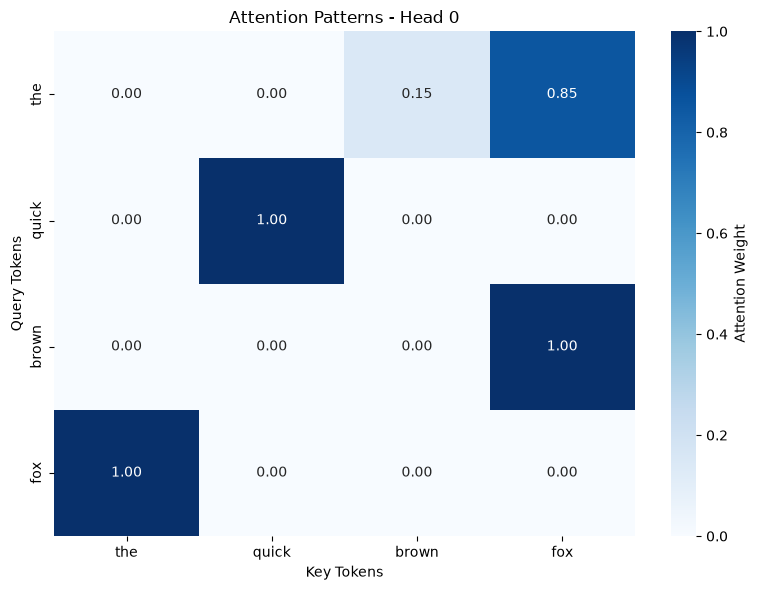

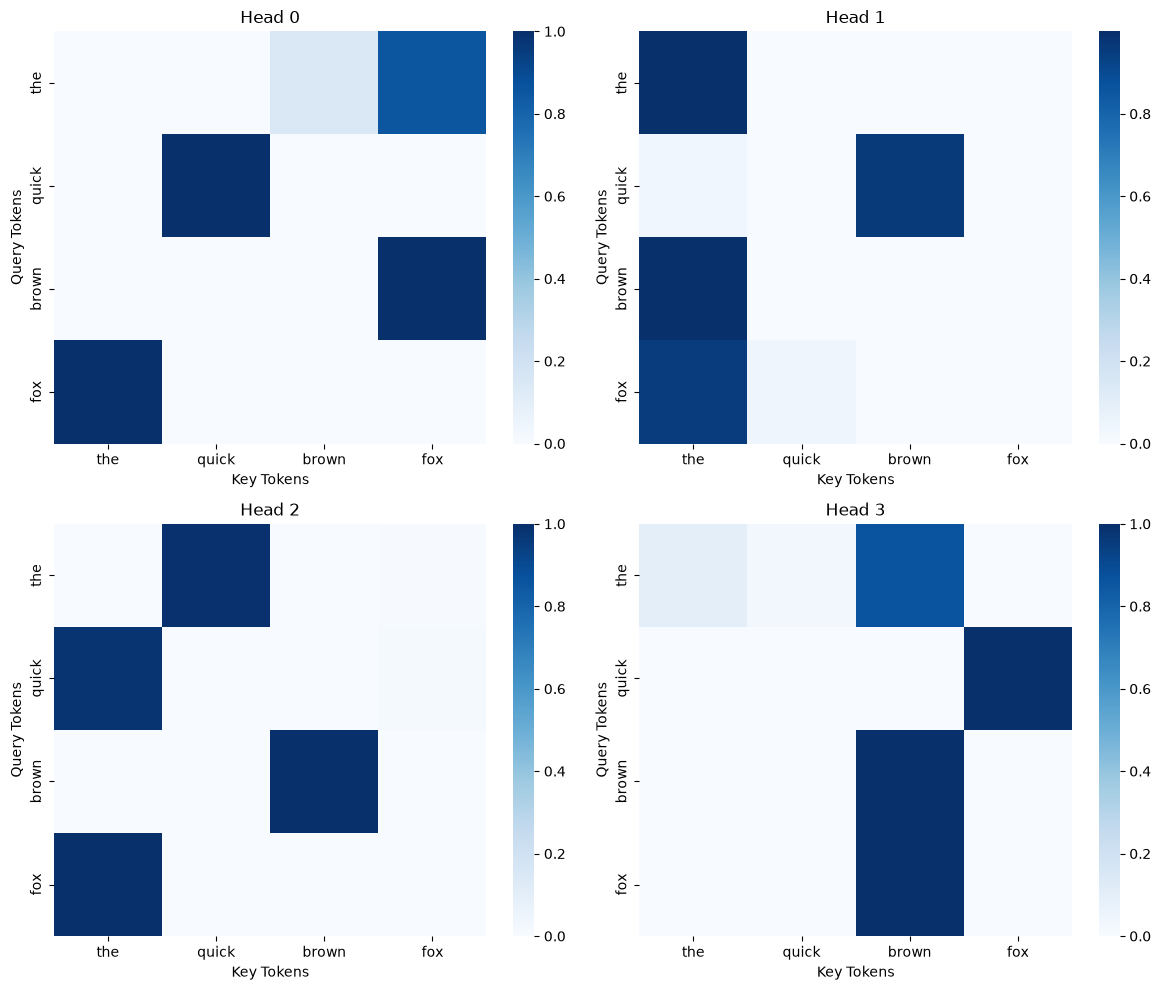

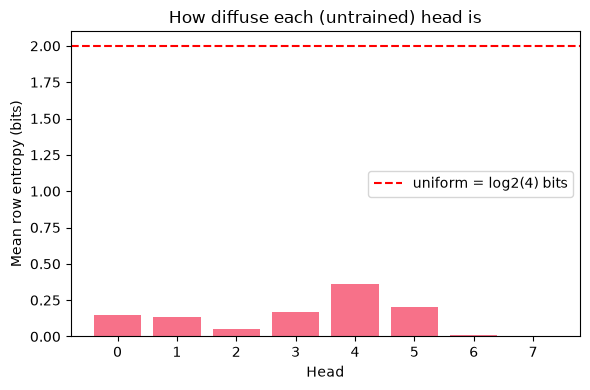

In [9]:
# Visualize attention patterns
def plot_attention_heatmap(attention_weights: torch.Tensor, tokens: list, head_idx: int = 0):
    """Plot attention weights as a heatmap."""
    # Extract attention weights for one head
    attn = attention_weights[0, head_idx].detach().numpy()
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(attn, 
                xticklabels=tokens,
                yticklabels=tokens,
                cmap='Blues',
                annot=True, fmt='.2f',
                cbar_kws={'label': 'Attention Weight'})
    plt.title(f'Attention Patterns - Head {head_idx}')
    plt.xlabel('Key Tokens')
    plt.ylabel('Query Tokens')
    plt.tight_layout()
    plt.show()

# Get tokens for visualization
test_tokens = ["the", "quick", "brown", "fox"]
plot_attention_heatmap(mha_weights, test_tokens, head_idx=0)

# Compare multiple attention heads
def plot_multiple_heads(attention_weights: torch.Tensor, tokens: list, num_heads_to_show: int = 4):
    """Plot attention patterns for multiple heads."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()
    
    for i in range(min(num_heads_to_show, attention_weights.size(1))):
        attn = attention_weights[0, i].detach().numpy()
        
        sns.heatmap(attn, 
                    xticklabels=tokens,
                    yticklabels=tokens,
                    cmap='Blues',
                    ax=axes[i],
                    cbar=True)
        axes[i].set_title(f'Head {i}')
        axes[i].set_xlabel('Key Tokens')
        axes[i].set_ylabel('Query Tokens')
    
    plt.tight_layout()
    plt.show()

plot_multiple_heads(mha_weights, test_tokens)


def head_entropies_bits(weights: torch.Tensor) -> torch.Tensor:
    """Mean row entropy (bits) per head: how spread out each head's attention is."""
    w = weights[0]                                                     # [heads, seq, seq]
    ent = -(w * torch.log2(w + 1e-12)).sum(-1)                         # [heads, seq], one value per row
    return ent.mean(-1)

ent = head_entropies_bits(mha_weights.detach())
assert (ent <= math.log2(mha_weights.size(-1)) + 1e-6).all(), "row entropy cannot exceed log2(seq_len)"
plt.figure(figsize=(6, 4))
plt.bar(range(len(ent)), ent)
plt.axhline(math.log2(mha_weights.size(-1)), color='r', linestyle='--', label=f'uniform = log2({mha_weights.size(-1)}) bits')
plt.xlabel('Head'); plt.ylabel('Mean row entropy (bits)'); plt.title('How diffuse each (untrained) head is'); plt.legend(); plt.tight_layout(); plt.show()


(nb-attn-transformer)=
## 4. Transformer Architecture Components

$$x \leftarrow \mathrm{LayerNorm}(x + \mathrm{MHA}(x)), \qquad x \leftarrow \mathrm{LayerNorm}(x + \mathrm{FFN}(x)), \qquad \mathrm{FFN}(x) = \max(0, xW_1 + b_1)W_2 + b_2$$

This is the original *post-LN* block (Vaswani et al., 2017). Most models since GPT-2 use *pre-LN* (normalize before each sublayer), RMSNorm, and a gated activation (SwiGLU) instead of ReLU; see the chapter's "What changed since 2017" section.

- **Multi-head attention** mixes information across positions
- **Feed-forward network** transforms each position independently
- **Layer normalization** (Ba et al., 2016) keeps activations at a fixed scale
- **Residual connections** (He et al., 2016) give gradients an identity path


In [10]:
class TransformerBlock(nn.Module):
    """Complete transformer block with attention and feed-forward layers."""
    
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.attention = MultiHeadAttention(d_model, num_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        
        # Feed-forward network
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )
        
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x: torch.Tensor, mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        # Multi-head attention with residual connection and layer norm
        attn_output, _ = self.attention(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_output))
        
        # Feed-forward with residual connection and layer norm
        ff_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_output))
        
        return x

# Test transformer block
d_ff = d_model * 4  # Typical feed-forward dimension
transformer_block = TransformerBlock(d_model, num_heads, d_ff).eval()

# Forward pass
block_output = transformer_block(embeddings)
print(f"Transformer block output shape: {block_output.shape}")
print(f"Input embeddings mean: {embeddings.mean():.4f}")
print(f"Output mean: {block_output.mean():.4f} (≈0 by construction: the block ends with a LayerNorm whose β is initialised to 0)")

Transformer block output shape: torch.Size([1, 4, 64])
Input embeddings mean: 0.3679
Output mean: 0.0000 (≈0 by construction: the block ends with a LayerNorm whose β is initialised to 0)


Before Layer Normalization:
Small scale - Mean: 0.0083, Std: 0.0980
Large scale - Mean: 0.5163, Std: 10.6274

After Layer Normalization:
Small scale - Mean: -0.0000, Std: 1.0014
Large scale - Mean: -0.0000, Std: 1.0020


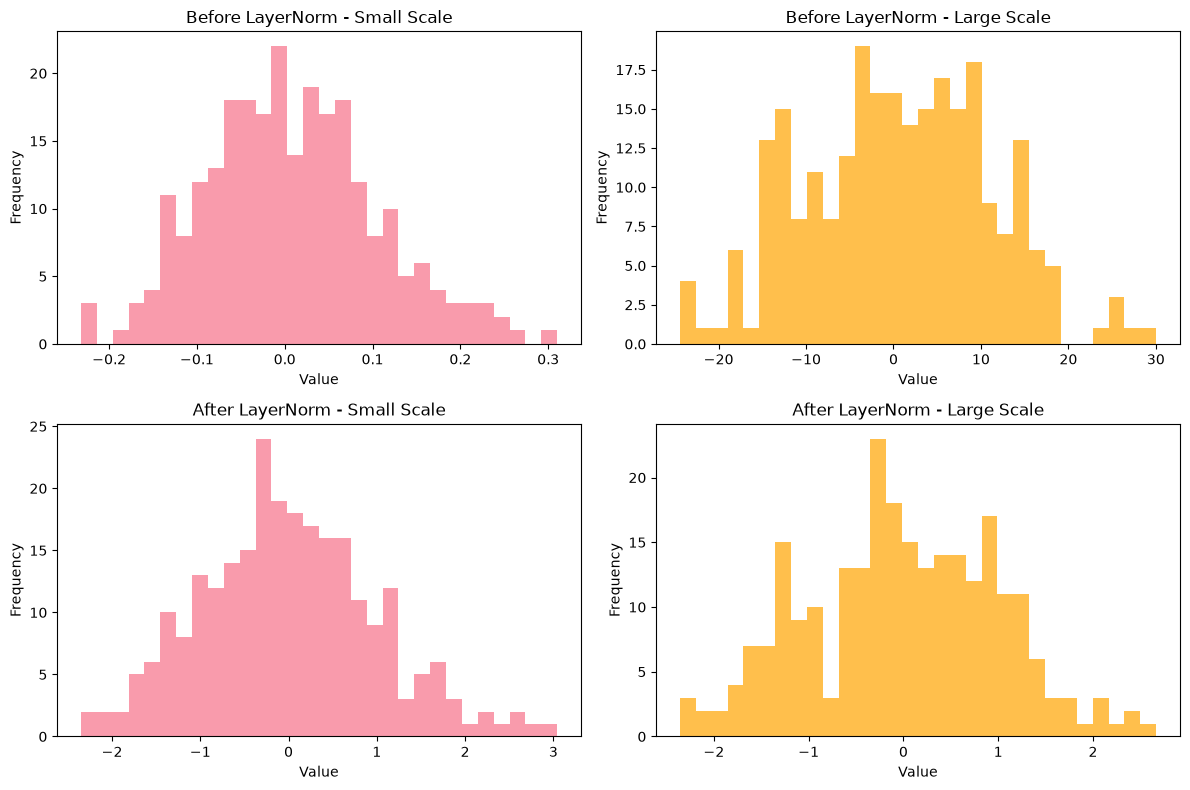

In [11]:
# Analyze the effect of layer normalization
def analyze_layer_norm_effect():
    """Show how layer normalization affects activations."""
    # Create some sample activations with different scales
    x1 = torch.randn(1, 4, d_model) * 0.1  # Small scale
    x2 = torch.randn(1, 4, d_model) * 10   # Large scale
    
    layer_norm = nn.LayerNorm(d_model)
    
    # Before layer norm
    print("Before Layer Normalization:")
    print(f"Small scale - Mean: {x1.mean():.4f}, Std: {x1.std():.4f}")
    print(f"Large scale - Mean: {x2.mean():.4f}, Std: {x2.std():.4f}")
    
    # After layer norm
    x1_norm = layer_norm(x1)
    x2_norm = layer_norm(x2)
    
    print("\nAfter Layer Normalization:")
    print(f"Small scale - Mean: {x1_norm.mean():.4f}, Std: {x1_norm.std():.4f}")
    print(f"Large scale - Mean: {x2_norm.mean():.4f}, Std: {x2_norm.std():.4f}")
    
    # Visualize the distribution
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    axes[0, 0].hist(x1.flatten().detach(), bins=30, alpha=0.7, label='Small scale')
    axes[0, 0].set_title('Before LayerNorm - Small Scale')
    axes[0, 0].set_xlabel('Value')
    axes[0, 0].set_ylabel('Frequency')
    
    axes[0, 1].hist(x2.flatten().detach(), bins=30, alpha=0.7, label='Large scale', color='orange')
    axes[0, 1].set_title('Before LayerNorm - Large Scale')
    axes[0, 1].set_xlabel('Value')
    axes[0, 1].set_ylabel('Frequency')
    
    axes[1, 0].hist(x1_norm.flatten().detach(), bins=30, alpha=0.7, label='Small scale normalized')
    axes[1, 0].set_title('After LayerNorm - Small Scale')
    axes[1, 0].set_xlabel('Value')
    axes[1, 0].set_ylabel('Frequency')
    
    axes[1, 1].hist(x2_norm.flatten().detach(), bins=30, alpha=0.7, label='Large scale normalized', color='orange')
    axes[1, 1].set_title('After LayerNorm - Large Scale')
    axes[1, 1].set_xlabel('Value')
    axes[1, 1].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()

analyze_layer_norm_effect()

(nb-attn-lm)=
## 5. Language Modeling Objective

$$\mathcal{L} = -\sum_{i} \log P(x_i \mid x_{<i}), \qquad P(x_i \mid x_{<i}) = \mathrm{softmax}(W_{\text{out}} h_{i-1}), \qquad \mathrm{PPL} = \exp\!\left(\frac{\mathcal{L}}{N}\right)$$

A causal mask stops position $i$ from attending to positions $> i$, so the hidden state at position $i-1$ can be used to predict token $i$.


Causal mask (True = attend, False = mask):
tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)


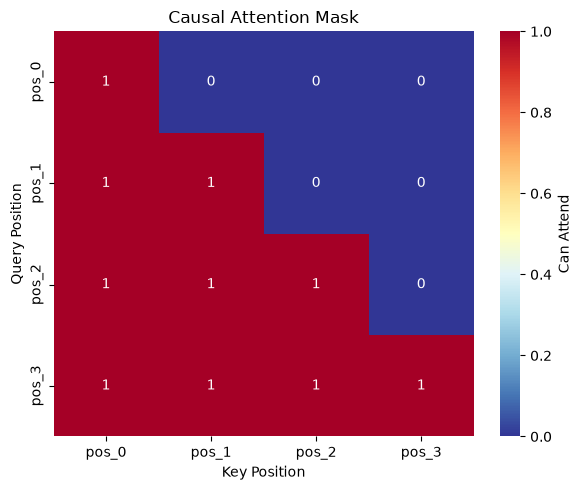


Masked attention output shape: torch.Size([1, 4, 64])


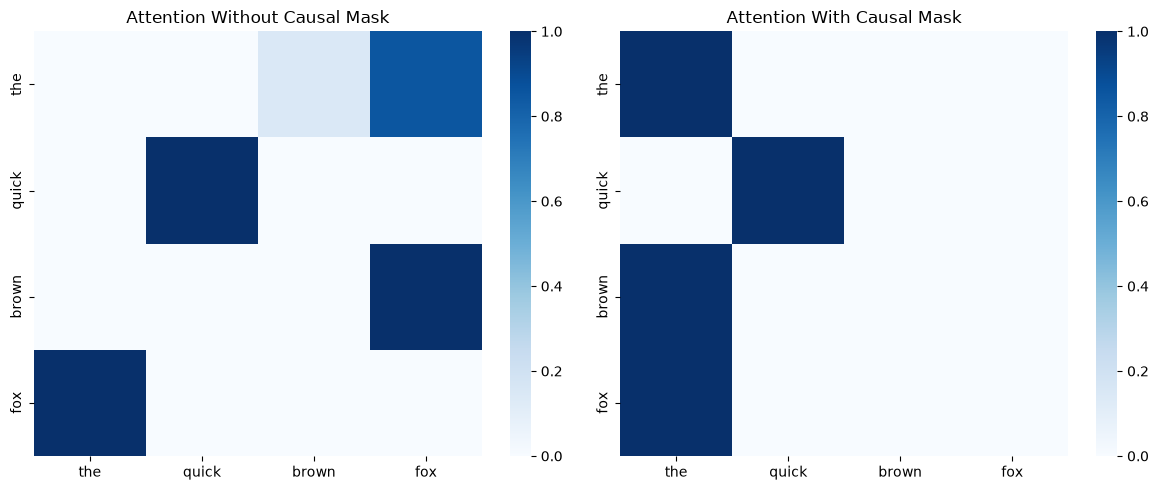

In [12]:
def create_causal_mask(seq_length: int) -> torch.Tensor:
    """Create a causal mask to prevent attention to future tokens."""
    mask = torch.triu(torch.ones(seq_length, seq_length), diagonal=1)
    return mask == 0  # True for allowed positions, False for masked

# Test causal masking
seq_len = 4
causal_mask = create_causal_mask(seq_len)
print("Causal mask (True = attend, False = mask):")
print(causal_mask.int())

# Visualize causal mask
plt.figure(figsize=(6, 5))
sns.heatmap(causal_mask.int(), 
            annot=True, 
            cmap='RdYlBu_r',
            xticklabels=[f'pos_{i}' for i in range(seq_len)],
            yticklabels=[f'pos_{i}' for i in range(seq_len)],
            cbar_kws={'label': 'Can Attend'})
plt.title('Causal Attention Mask')
plt.xlabel('Key Position')
plt.ylabel('Query Position')
plt.tight_layout()
plt.show()

# Apply causal mask to attention
causal_mask_expanded = causal_mask.unsqueeze(0).unsqueeze(0)  # Add batch and head dims
masked_output, masked_weights = mha(embeddings, embeddings, embeddings, causal_mask_expanded)

print(f"\nMasked attention output shape: {masked_output.shape}")

# Compare attention patterns with and without causal mask
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Without mask
attn_no_mask = mha_weights[0, 0].detach().numpy()
sns.heatmap(attn_no_mask, 
            xticklabels=test_tokens,
            yticklabels=test_tokens,
            cmap='Blues', ax=axes[0],
            cbar=True)
axes[0].set_title('Attention Without Causal Mask')

# With mask
attn_with_mask = masked_weights[0, 0].detach().numpy()
sns.heatmap(attn_with_mask, 
            xticklabels=test_tokens,
            yticklabels=test_tokens,
            cmap='Blues', ax=axes[1],
            cbar=True)
axes[1].set_title('Attention With Causal Mask')

plt.tight_layout()
plt.show()

In [13]:
# Simple language model head
class LanguageModelHead(nn.Module):
    """Language model head for next-token prediction."""
    
    def __init__(self, d_model: int, vocab_size: int):
        super().__init__()
        self.linear = nn.Linear(d_model, vocab_size)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear(x)

# Create language model head
lm_head = LanguageModelHead(d_model, vocab_size)

# Get logits for next token prediction
logits = lm_head(block_output)
print(f"Language model logits shape: {logits.shape}")

# Convert to probabilities
probabilities = F.softmax(logits, dim=-1)
print(f"Probabilities shape: {probabilities.shape}")
print(f"Probability sum for last position: {probabilities[0, -1, :].sum():.4f}")

# Calculate perplexity for a simple example
def calculate_perplexity(logits: torch.Tensor, targets: torch.Tensor) -> float:
    """Calculate perplexity from logits and targets."""
    loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
    return torch.exp(loss).item()

# Create simple targets (next tokens)
input_text = "the quick brown"
target_text = "quick brown fox"

input_ids = torch.tensor([tokenize(input_text)])
target_ids = torch.tensor([tokenize(target_text)])

# Forward pass through our simple model
embeddings = embedding_layer(input_ids)
transformer_output = transformer_block(embeddings)
logits = lm_head(transformer_output)

# Calculate perplexity
perplexity = calculate_perplexity(logits, target_ids)
print(f"\nPerplexity of this UNTRAINED model: {perplexity:.2f}  (a uniform guess over {vocab_size} tokens would give {vocab_size}; training drives this down)")

# Show predicted vs actual next tokens
print("\nPredicted vs actual next tokens (random weights, so matches are chance):")
for i in range(input_ids.size(1)):
    predicted_id = logits[0, i].argmax().item()
    actual_id = target_ids[0, i].item()
    
    # Find token for predicted ID
    predicted_token = [k for k, v in vocab.items() if v == predicted_id][0]
    actual_token = [k for k, v in vocab.items() if v == actual_id][0]
    
    print(f"Position {i}: Predicted='{predicted_token}', Actual='{actual_token}'")

Language model logits shape: torch.Size([1, 4, 9])
Probabilities shape: torch.Size([1, 4, 9])
Probability sum for last position: 1.0000

Perplexity of this UNTRAINED model: 11.36  (a uniform guess over 9 tokens would give 9; training drives this down)

Predicted vs actual next tokens (random weights, so matches are chance):
Position 0: Predicted='<UNK>', Actual='quick'
Position 1: Predicted='fox', Actual='brown'
Position 2: Predicted='the', Actual='fox'


(nb-attn-further)=
## 6. Where the rest lives

Information theory, optimizers and learning-rate schedules, gradient flow through LayerNorm and residual connections, scaling laws and numerical stability are implemented, with assertions, in the [Mathematical Foundations notebook](../../02-mathematics/examples/mathematical_foundations_demo.ipynb).


## What this notebook covered

- A word-level tokenizer and the BPE merge loop (subword tokenizers in depth: the chapter's tokenization sections)
- Token embeddings with sinusoidal positions; learned, relative-bias and rotary alternatives, with RoPE's norm-preservation and relative-offset properties asserted
- Scaled dot-product and multi-head attention in eval mode, rows asserted to sum to 1, plus per-head attention entropy
- A post-LN transformer block and the causal mask
- The next-token objective and the perplexity of an untrained model

For the explanations behind each piece, return to the [Foundations chapter](../index.md).
